Stage 1 — Dataset quality: 
Class distribution, empty labels, annotation validation, duplicate detection.

In [9]:
from pathlib import Path

In [10]:
from pathlib import Path

# Dataset path relative to the notebooks directory
DATASET_PATH = Path("../data/RDD_SPLIT").resolve()

# Verify dataset exists
assert DATASET_PATH.is_dir(), f"Dataset not found: {DATASET_PATH}"

print(f"Dataset path: {DATASET_PATH}")

Dataset path: C:\Users\Dinuka\Documents\GitHub\RoadLens\ml\c1\data\RDD_SPLIT


In [11]:

import pandas as pd

dataset_stats = []

for split in ["train", "val", "test"]:
    images_dir = DATASET_PATH / split / "images"
    labels_dir = DATASET_PATH / split / "labels"

    image_files = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    label_files = list(labels_dir.glob("*.txt"))

    dataset_stats.append({
        "Split": split,
        "Images": len(image_files),
        "Label Files": len(label_files),
        "Images Without Label Files": len(
            {p.stem for p in image_files}
            - {p.stem for p in label_files}
        )
    })

df_stats = pd.DataFrame(dataset_stats)
display(df_stats)


,Split,Images,Label Files,Images Without Label Files
0,train,26869,26869,0
1,val,5758,5758,0
2,test,5758,5758,0


In [12]:

from collections import Counter
import pandas as pd

class_counts = {}
empty_labels = {}

for split in ["train", "val", "test"]:
    labels_dir = DATASET_PATH / split / "labels"
    counts = Counter()
    empty_count = 0

    for label_path in labels_dir.glob("*.txt"):
        lines = label_path.read_text(encoding="utf-8").splitlines()

        if not lines:
            empty_count += 1

        for line in lines:
            parts = line.strip().split()
            if parts:
                class_id = int(parts[0])
                counts[class_id] += 1

    class_counts[split] = counts
    empty_labels[split] = empty_count

all_classes = sorted(
    set().union(*(counts.keys() for counts in class_counts.values()))
)

df_classes = pd.DataFrame({
    split: [class_counts[split][cls] for cls in all_classes]
    for split in ["train", "val", "test"]
}, index=all_classes)

df_classes.index.name = "Class ID"
df_classes["Total"] = df_classes.sum(axis=1)

display(df_classes)

print("\nEmpty annotation files:")
print(empty_labels)


,train,val,test,Total
Class ID,,,,
0,18201,3890,3925,26016
1,8386,1769,1675,11830
2,7527,1553,1537,10617
3,7554,1564,1587,10705
4,4628,965,951,6544



Empty annotation files:
{'train': 8097, 'val': 1837, 'test': 1790}


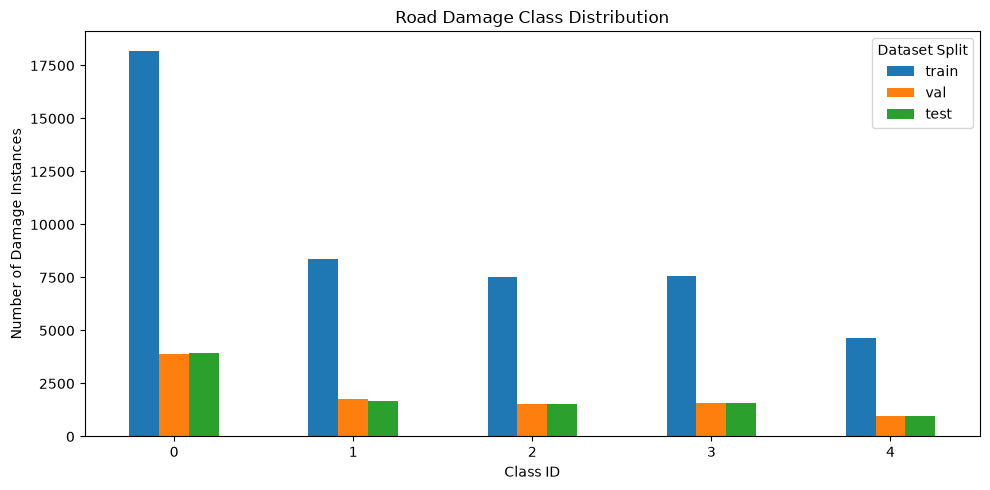

In [14]:

import matplotlib.pyplot as plt

ax = df_classes[["train", "val", "test"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Road Damage Class Distribution")
plt.xlabel("Class ID")
plt.ylabel("Number of Damage Instances")
plt.xticks(rotation=0)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()


Stage 2 — Visual characteristics: 
Image resolutions, bounding-box statistics, visual samples and image quality.

Stage 3 — Domain analysis: 
Country distributions, capture-source differences and split composition.